# 02 · Validating the degradation estimates

Notebook 01 found something suspicious: in 2026, softs barely wear (about 0.005 s/lap) and a new soft looks *slower* than a new medium. Before 2026, softs looked normal. This notebook tests three explanations:

1. **Noise:** too few soft laps to measure anything precisely. → *Add confidence ranges.*
2. **Usage:** softs used mostly in unusual parts of the race. → *Look at where softs are used.*
3. **Start-of-race traffic:** slow, bunched-up early laps make first-stint tires look slow and hide their wear. → *Refit without the opening laps.*

In [1]:
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

from degradation import bootstrap, fit_degradation, summarize

COMPOUND_COLORS = {"SOFT": "#E10600", "MEDIUM": "#F5C400", "HARD": "#9A9A9A"}
REF_LAP = 90  # seconds; converts % into seconds on a typical lap

laps = pd.read_parquet(Path("..") / "app" / "data" / "clean_laps.parquet")
SEASON = int(laps["SEASON"].max())
periods = {f"{SEASON}": laps[laps["SEASON"] == SEASON],
           f"before {SEASON}": laps[laps["SEASON"] < SEASON]}
{name: f"{len(d):,} laps, {d[['SEASON', 'RACE_ROUND']].drop_duplicates().shape[0]} races"
 for name, d in periods.items()}

{'2026': '16,340 laps, 17 races', 'before 2026': '64,101 laps, 69 races'}

## 1. Confidence ranges

**Bootstrapping:** refit the model 200 times, each time on a random set of races drawn with replacement from the real ones. Some races appear twice, some not at all. The spread of the 200 answers shows how much the result depends on which races happened to be in the data.

Whole races are resampled, not individual laps, because laps from the same race share weather, track, and traffic. Treating them as independent would make the ranges look more precise than they are.

This cell takes a minute or two.

In [2]:
results = {}
for name, d in periods.items():
    boot = bootstrap(d, n=200)
    results[name] = summarize(fit_degradation(d), boot, REF_LAP)

table = pd.concat(results, names=["period", "term"]).round(3)
table

estimate  low (2.5%)  high (97.5%)
period      term                                           
2026        fuel           -0.043      -0.050        -0.037
            deg_SOFT        0.005      -0.024         0.031
            deg_MEDIUM      0.028       0.016         0.041
            deg_HARD        0.026       0.009         0.051
            offset_SOFT     0.257      -0.107         0.649
            offset_HARD     0.016      -0.254         0.225
before 2026 fuel           -0.054      -0.057        -0.051
            deg_SOFT        0.059       0.043         0.075
            deg_MEDIUM      0.036       0.025         0.046
            deg_HARD        0.034       0.025         0.042
            offset_SOFT    -0.341      -0.558        -0.091
            offset_HARD    -0.003      -0.143         0.165

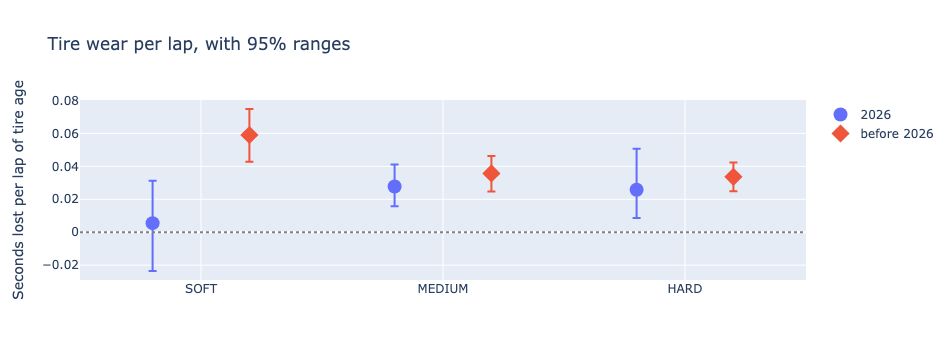

In [3]:
fig = go.Figure()
for name, symbol in zip(results, ["circle", "diamond"]):
    r = results[name].loc[["deg_SOFT", "deg_MEDIUM", "deg_HARD"]]
    fig.add_trace(go.Scatter(
        x=["SOFT", "MEDIUM", "HARD"], y=r["estimate"], name=name, mode="markers",
        marker=dict(size=14, symbol=symbol),
        error_y=dict(type="data", symmetric=False,
                     array=r["high (97.5%)"] - r["estimate"],
                     arrayminus=r["estimate"] - r["low (2.5%)"])))
fig.update_layout(title="Tire wear per lap, with 95% ranges",
                  yaxis_title="Seconds lost per lap of tire age", scattermode="group")
fig.add_hline(y=0, line_dash="dot", line_color="gray")
fig.show()

**How to read this:** if the two ranges for a compound overlap a lot, the data can't tell the periods apart, and the difference is likely noise. If a range crosses zero, the data can't rule out "no measurable wear" for that compound.

## 2. Where softs are used

If 2026 softs are mostly run at one point in the race (say, the opening stint), their numbers reflect that situation as much as the tire.

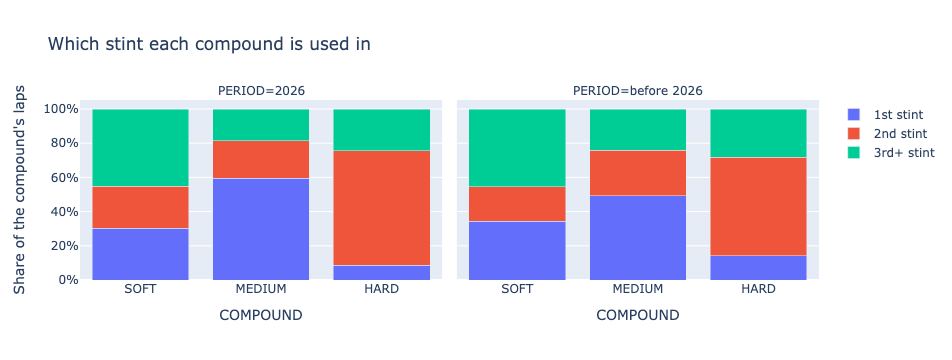

In [4]:
dry = laps[laps["COMPOUND"].isin(COMPOUND_COLORS)].copy()
dry["PERIOD"] = dry["SEASON"].map(lambda s: f"{SEASON}" if s == SEASON else f"before {SEASON}")
dry["STINT_GROUP"] = dry["STINT"].clip(upper=3).map({1: "1st stint", 2: "2nd stint", 3: "3rd+ stint"})

usage = (dry.groupby(["PERIOD", "COMPOUND", "STINT_GROUP"]).size()
         .groupby(level=[0, 1]).transform(lambda s: s / s.sum()).rename("share").reset_index())
fig = px.bar(usage, x="COMPOUND", y="share", color="STINT_GROUP", facet_col="PERIOD",
             barmode="stack", category_orders={"COMPOUND": list(COMPOUND_COLORS)},
             labels={"share": "Share of the compound's laps", "STINT_GROUP": ""},
             title="Which stint each compound is used in")
fig.update_yaxes(tickformat=".0%")
fig.show()

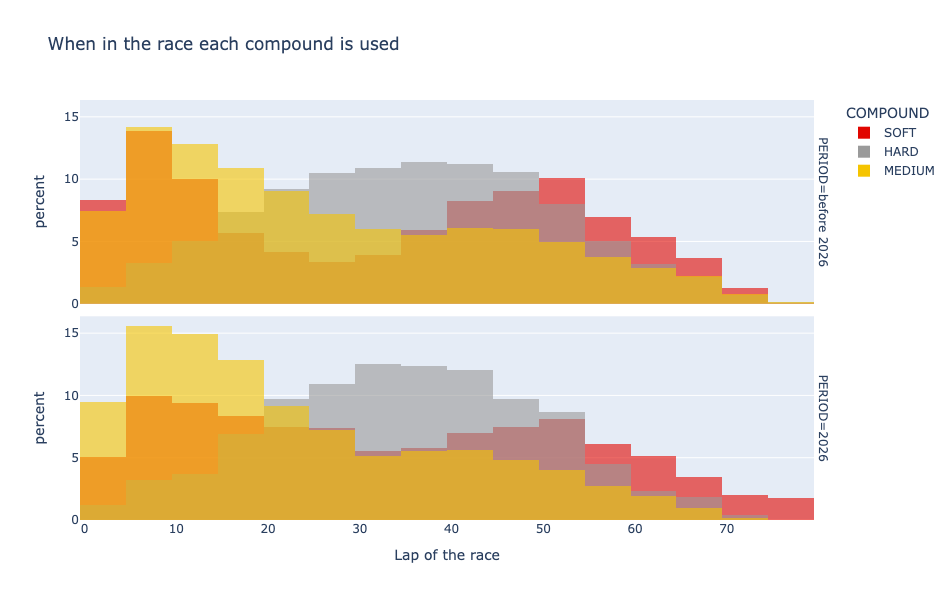

In [5]:
fig = px.histogram(dry, x="LAP_NUMBER", color="COMPOUND", facet_row="PERIOD",
                   color_discrete_map=COMPOUND_COLORS, histnorm="percent", nbins=35,
                   barmode="overlay", opacity=0.6,
                   labels={"LAP_NUMBER": "Lap of the race"},
                   title="When in the race each compound is used")
fig.update_layout(height=600)
fig.show()

## 3. Does start-of-race traffic distort the result?

Refit while dropping the first few laps of every race. If traffic is the problem, the soft numbers should move toward normal (more wear, and a faster new tire) as more opening laps are removed. If they barely move, traffic isn't the explanation.

In [6]:
rows = []
for skip in [0, 3, 5, 8]:
    for name, d in periods.items():
        est = fit_degradation(d[d["LAP_NUMBER"] > 1 + skip]) * REF_LAP / 100
        rows.append({"laps dropped after lap 1": skip, "period": name,
                     "SOFT wear": est["deg_SOFT"], "MEDIUM wear": est["deg_MEDIUM"],
                     "HARD wear": est["deg_HARD"],
                     "new SOFT vs new MEDIUM (s)": est["offset_SOFT"]})
sens = pd.DataFrame(rows).set_index(["period", "laps dropped after lap 1"]).sort_index()
sens.round(3)

SOFT wear  MEDIUM wear  HARD wear  \
period      laps dropped after lap 1                                      
2026        0                             0.005        0.028      0.026   
            3                             0.013        0.031      0.027   
            5                             0.017        0.030      0.029   
            8                             0.021        0.030      0.030   
before 2026 0                             0.059        0.036      0.034   
            3                             0.063        0.038      0.035   
            5                             0.065        0.039      0.035   
            8                             0.067        0.039      0.035   

                                      new SOFT vs new MEDIUM (s)  
period      laps dropped after lap 1                              
2026        0                                              0.257  
            3                                              0.171  
            5                                              0.084  
            8                                              0.002  
before 2026 0                                             -0.341  
            3                                             -0.381  
            5                                             -0.398  
            8                                             -0.468

**How to read this:** a negative "new SOFT vs new MEDIUM" is normal (softs start faster). Watch whether the 2026 value turns negative, and whether SOFT wear rises, as more opening laps are dropped.

## What the results mean

Each outcome points to a different next step:

- **The 2026 soft range is wide and overlaps the earlier one:** the odd result is mostly noise. Report it with its range, and lean on earlier seasons for softs until 2026 has more data.
- **Softs are concentrated in one stint and dropping opening laps shifts the numbers:** traffic is distorting the measurement. Drop those laps by default in `CLEAN_LAPS` or in the model.
- **Neither:** 2026 softs may genuinely behave differently under the new rules, and that's a finding worth writing up.